# Câu 3b–3c: Mosaic Plot vs Marimekko Chart

Notebook này tạo lại dataset mô phỏng ngành thương mại điện tử/giao hàng chặng cuối, sau đó vẽ:

1. **Marimekko Chart**: chiều rộng cột và diện tích ô được xác định bởi `doanh_thu_trieu_vnd`.
2. **Mosaic Plot**: chiều rộng cột và diện tích ô được xác định bởi `so_don_hang`.

Chạy trực tiếp trên Google Colab, không cần upload thêm file CSV.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import textwrap

# Dataset từ câu a
data = [
    ["TP.HCM", "Giao nhanh trong ngày", 1750, 5000],
    ["TP.HCM", "Giao tiêu chuẩn", 1260, 4200],
    ["TP.HCM", "Giao xanh / điểm nhận hàng", 560, 1600],
    ["Hà Nội", "Giao nhanh trong ngày", 1800, 3600],
    ["Hà Nội", "Giao tiêu chuẩn", 1350, 3000],
    ["Hà Nội", "Giao xanh / điểm nhận hàng", 660, 1200],
    ["Đà Nẵng", "Giao nhanh trong ngày", 520, 1300],
    ["Đà Nẵng", "Giao tiêu chuẩn", 570, 1500],
    ["Đà Nẵng", "Giao xanh / điểm nhận hàng", 360, 900],
]

df = pd.DataFrame(data, columns=["khu_vuc", "phuong_thuc_giao_hang", "doanh_thu_trieu_vnd", "so_don_hang"])
df


,khu_vuc,phuong_thuc_giao_hang,doanh_thu_trieu_vnd,so_don_hang
0,TP.HCM,Giao nhanh trong ngày,1750,5000
1,TP.HCM,Giao tiêu chuẩn,1260,4200
2,TP.HCM,Giao xanh / điểm nhận hàng,560,1600
3,Hà Nội,Giao nhanh trong ngày,1800,3600
4,Hà Nội,Giao tiêu chuẩn,1350,3000
5,Hà Nội,Giao xanh / điểm nhận hàng,660,1200
6,Đà Nẵng,Giao nhanh trong ngày,520,1300
7,Đà Nẵng,Giao tiêu chuẩn,570,1500
8,Đà Nẵng,Giao xanh / điểm nhận hàng,360,900


In [ ]:
# Lưu lại CSV để nộp kèm nếu cần
df.to_csv("ecommerce_delivery_mosaic_marimekko_dataset.csv", index=False, encoding="utf-8-sig")
print("Đã lưu file: ecommerce_delivery_mosaic_marimekko_dataset.csv")


Đã lưu file: ecommerce_delivery_mosaic_marimekko_dataset.csv


In [ ]:
# Bảng tổng hợp nhanh để kiểm tra giả thuyết trước khi vẽ
summary_region = df.groupby("khu_vuc", as_index=False).agg(
    doanh_thu_trieu_vnd=("doanh_thu_trieu_vnd", "sum"),
    so_don_hang=("so_don_hang", "sum")
)
summary_region["aov_trieu_vnd_moi_don"] = summary_region["doanh_thu_trieu_vnd"] / summary_region["so_don_hang"]
summary_region


,khu_vuc,doanh_thu_trieu_vnd,so_don_hang,aov_trieu_vnd_moi_don
0,Hà Nội,3810,7800,0.488462
1,TP.HCM,3570,10800,0.330556
2,Đà Nẵng,1450,3700,0.391892


In [ ]:
# Helper vẽ biểu đồ dạng variable-width stacked rectangles.
# value_col = doanh_thu_trieu_vnd => Marimekko
# value_col = so_don_hang => Mosaic

def wrap_label(text, width=16):
    return "\n".join(textwrap.wrap(str(text), width=width))

def draw_variable_width_chart(df, value_col, title, value_label, figsize=(11, 6)):
    x_categories = list(df["khu_vuc"].drop_duplicates())
    y_categories = list(df["phuong_thuc_giao_hang"].drop_duplicates())

    total_value = df[value_col].sum()
    region_totals = df.groupby("khu_vuc")[value_col].sum().reindex(x_categories)

    fig, ax = plt.subplots(figsize=figsize)
    color_cycle = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    color_map = {cat: color_cycle[i % len(color_cycle)] for i, cat in enumerate(y_categories)}

    x_left = 0
    xtick_positions = []
    xtick_labels = []

    for region in x_categories:
        region_total = region_totals.loc[region]
        width = region_total / total_value
        y_bottom = 0

        region_df = df[df["khu_vuc"] == region].set_index("phuong_thuc_giao_hang").reindex(y_categories).reset_index()

        for _, row in region_df.iterrows():
            segment = row[value_col]
            height = segment / region_total
            category = row["phuong_thuc_giao_hang"]
            share_total = segment / total_value * 100
            share_region = height * 100

            rect = plt.Rectangle(
                (x_left, y_bottom), width, height,
                facecolor=color_map[category],
                edgecolor="white", linewidth=1.2, alpha=0.85
            )
            ax.add_patch(rect)

            # Chỉ ghi nhãn khi ô đủ lớn để tránh rối
            if width > 0.11 and height > 0.16:
                label = f"{wrap_label(category, 13)}\n{segment:,.0f}\n{share_region:.1f}% trong vùng"
                ax.text(
                    x_left + width / 2, y_bottom + height / 2,
                    label, ha="center", va="center", fontsize=8
                )
            elif width * height > 0.025:
                ax.text(
                    x_left + width / 2, y_bottom + height / 2,
                    f"{share_total:.1f}%", ha="center", va="center", fontsize=8
                )

            y_bottom += height

        xtick_positions.append(x_left + width / 2)
        xtick_labels.append(f"{region}\n{region_total:,.0f}")
        ax.text(x_left + width / 2, 1.025, f"{width*100:.1f}%", ha="center", va="bottom", fontsize=9)
        x_left += width

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.08)
    ax.set_xticks(xtick_positions)
    ax.set_xticklabels(xtick_labels)
    ax.set_yticks([])
    ax.set_xlabel(f"Chiều rộng cột theo tổng {value_label} của khu vực")
    ax.set_title(title, fontsize=14, pad=18)

    handles = [plt.Rectangle((0, 0), 1, 1, facecolor=color_map[cat], alpha=0.85) for cat in y_categories]
    ax.legend(handles, y_categories, title="Phương thức giao hàng", bbox_to_anchor=(1.02, 1), loc="upper left")
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.grid(False)
    plt.tight_layout()
    plt.show()


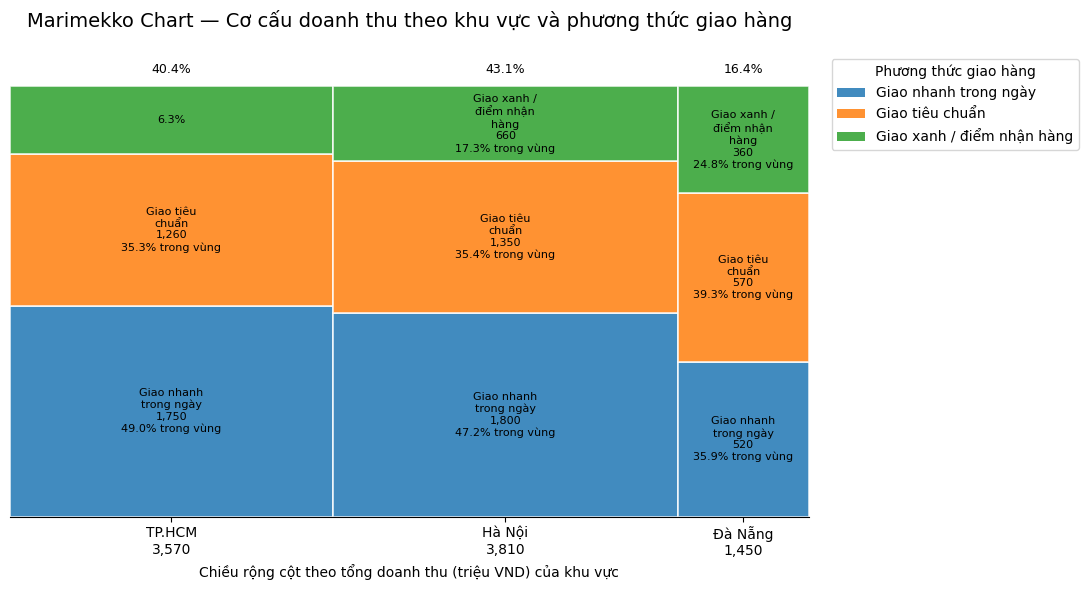

In [ ]:
draw_variable_width_chart(
    df,
    value_col="doanh_thu_trieu_vnd",
    title="Marimekko Chart — Cơ cấu doanh thu theo khu vực và phương thức giao hàng",
    value_label="doanh thu (triệu VND)"
)


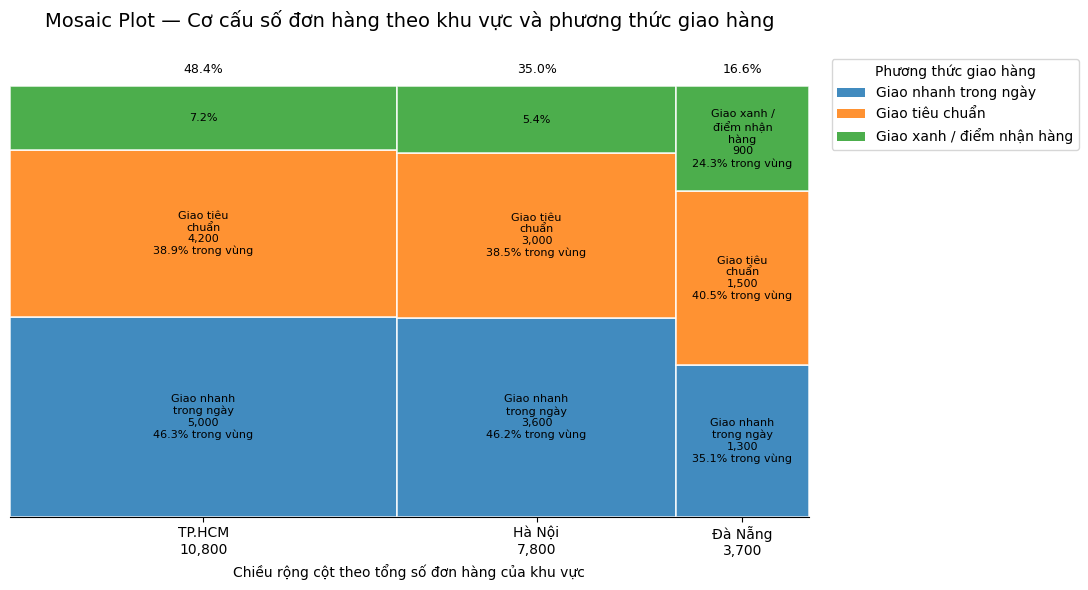

In [ ]:
draw_variable_width_chart(
    df,
    value_col="so_don_hang",
    title="Mosaic Plot — Cơ cấu số đơn hàng theo khu vực và phương thức giao hàng",
    value_label="số đơn hàng"
)


In [ ]:
# Bảng đối chiếu tỷ trọng để viết phần nhận xét
region_revenue = df.pivot(index="khu_vuc", columns="phuong_thuc_giao_hang", values="doanh_thu_trieu_vnd")
region_orders = df.pivot(index="khu_vuc", columns="phuong_thuc_giao_hang", values="so_don_hang")

print("Tỷ trọng doanh thu theo khu vực (% trong tổng doanh thu):")
print((region_revenue.sum(axis=1) / region_revenue.values.sum() * 100).round(1))

print("\nTỷ trọng số đơn theo khu vực (% trong tổng số đơn):")
print((region_orders.sum(axis=1) / region_orders.values.sum() * 100).round(1))

print("\nCơ cấu doanh thu trong từng khu vực (%):")
print((region_revenue.div(region_revenue.sum(axis=1), axis=0) * 100).round(1))

print("\nCơ cấu số đơn trong từng khu vực (%):")
print((region_orders.div(region_orders.sum(axis=1), axis=0) * 100).round(1))


Tỷ trọng doanh thu theo khu vực (% trong tổng doanh thu):
khu_vuc
Hà Nội     43.1
TP.HCM     40.4
Đà Nẵng    16.4
dtype: float64

Tỷ trọng số đơn theo khu vực (% trong tổng số đơn):
khu_vuc
Hà Nội     35.0
TP.HCM     48.4
Đà Nẵng    16.6
dtype: float64

Cơ cấu doanh thu trong từng khu vực (%):
phuong_thuc_giao_hang  Giao nhanh trong ngày  Giao tiêu chuẩn  \
khu_vuc                                                         
Hà Nội                                  47.2             35.4   
TP.HCM                                  49.0             35.3   
Đà Nẵng                                 35.9             39.3   

phuong_thuc_giao_hang  Giao xanh / điểm nhận hàng  
khu_vuc                                            
Hà Nội                                       17.3  
TP.HCM                                       15.7  
Đà Nẵng                                      24.8  

Cơ cấu số đơn trong từng khu vực (%):
phuong_thuc_giao_hang  Giao nhanh trong ngày  Giao tiêu chuẩn  \
khu_vuc        